# Machine Learning: Spam vs Ham SMS Classification & Clustering
**Part:** Machine Learning (Supervised Classification + K-Means Clustering)

Dataset: SMS messages labelled `ham` (legitimate) or `spam`.

1. **Supervised classification:** train/test split, TF-IDF, Multinomial Naive Bayes and Logistic Regression, Accuracy / Precision / Recall / F1, confusion matrix, interpretation and limitations.
2. **K-Means clustering:** TF-IDF + SVD representation, choosing *k*, cluster sizes, silhouette score, top terms per cluster, comparison with the original labels.

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             silhouette_score, adjusted_rand_score, normalized_mutual_info_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import Normalizer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("output", exist_ok=True)   # bind-mounted to the host in Docker

## 0. Load & prepare the data
The original text is kept in `message`; the model uses `cleaned_text`.

In [2]:
# Try common locations so the notebook works locally and inside Docker
for p in ["Dataset.csv", "data/Dataset.csv", "../data/Dataset.csv", "/home/jovyan/work/Dataset.csv", "/home/jovyan/data/Dataset.csv"]:
    if os.path.exists(p):
        DATA_PATH = p; break
else:
    raise FileNotFoundError("Dataset.csv not found - put it next to the notebook or in data/")

df = pd.read_csv(DATA_PATH, encoding="latin-1")[["label", "message"]]
print("Loaded from:", DATA_PATH, "| shape:", df.shape)

# Basic quality handling
df = df.dropna(subset=["label", "message"]).drop_duplicates().reset_index(drop=True)

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"[^a-z0-9\s]", " ", t)      # remove punctuation / symbols
    t = re.sub(r"\s+", " ", t).strip()       # normalise whitespace
    return t

df["cleaned_text"] = df["message"].apply(clean_text)
df = df[df["cleaned_text"].str.len() > 0].reset_index(drop=True)
df["y"] = (df["label"] == "spam").astype(int)   # spam = 1 (positive class), ham = 0

print("After removing duplicates:", df.shape)
print(df["label"].value_counts().to_string())
print(f"Spam ratio: {df['y'].mean():.2%}")
df.head()

Loaded from: Dataset.csv | shape: (5572, 2)
After removing duplicates: (5167, 4)
label
ham     4514
spam     653
Spam ratio: 12.64%


,label,message,cleaned_text,y
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,0
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,1
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,0


# Part 1: Supervised Classification

## 1.1 Train / Test split
An **80/20 stratified split** is used. The classes are imbalanced (spam is a small minority), so stratification keeps the same spam ratio in both sets.

In [3]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["cleaned_text"], df["y"], test_size=0.20, stratify=df["y"], random_state=RANDOM_STATE)

print("Train:", X_train_txt.shape[0], "| Test:", X_test_txt.shape[0])
print("Spam ratio train: %.2f%% | test: %.2f%%" % (y_train.mean()*100, y_test.mean()*100))

Train: 4133 | Test: 1034
Spam ratio train: 12.63% | test: 12.67%


## 1.2 TF-IDF features
TF-IDF is **fit on the training set only** (no data leakage) and then applied to the test set. Unigrams + bigrams, English stop-words removed, words appearing in fewer than 2 messages ignored.

In [4]:
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(X_train_txt)
X_test  = tfidf.transform(X_test_txt)
print("TF-IDF matrix (train):", X_train.shape, "| (test):", X_test.shape)

TF-IDF matrix (train): (4133, 5625) | (test): (1034, 5625)


## 1.3 Train the models
Two models are compared: **Multinomial Naive Bayes** (fast, classic for text) and **Logistic Regression** (with `class_weight="balanced"` to compensate for the imbalance).

In [5]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
}

rows, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test); preds[name] = p
    rows.append({"Model": name,
                 "Accuracy":  accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall":    recall_score(y_test, p),
                 "F1-score":  f1_score(y_test, p)})

results = pd.DataFrame(rows).set_index("Model").round(4)
results.to_csv("output/classification_metrics.csv")
results

,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial Naive Bayes,0.9845,0.9752,0.9008,0.9365
Logistic Regression,0.9768,0.9023,0.9160,0.9091


Precision, Recall and F1 are computed for the **spam** class (positive class = 1), since that is the class we care about detecting.

In [6]:
best_name = results["F1-score"].idxmax()
print("Best model by F1-score:", best_name)
print()
print(classification_report(y_test, preds[best_name], target_names=["ham", "spam"], digits=4))

Best model by F1-score: Multinomial Naive Bayes

              precision    recall  f1-score   support

         ham     0.9858    0.9967    0.9912       903
        spam     0.9752    0.9008    0.9365       131

    accuracy                         0.9845      1034
   macro avg     0.9805    0.9487    0.9638      1034
weighted avg     0.9844    0.9845    0.9843      1034



## 1.4 Confusion matrices

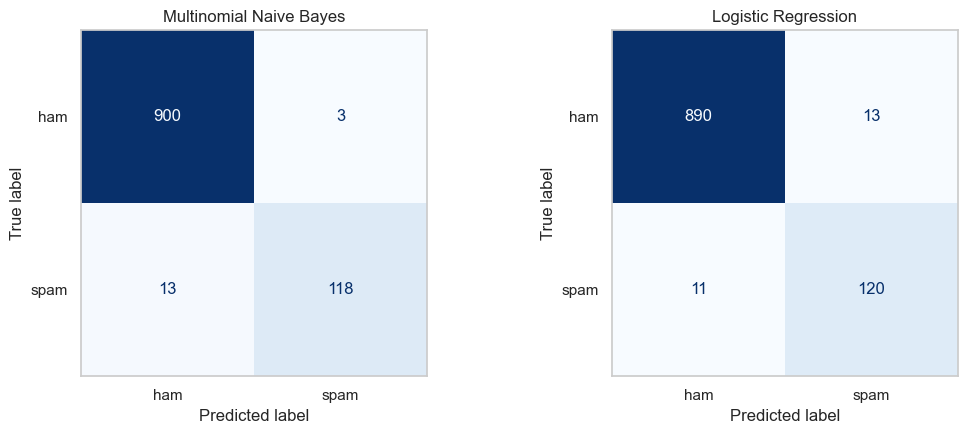

Multinomial Naive Bayes: TN=900  FP=3  FN=13  TP=118
Logistic Regression: TN=890  FP=13  FN=11  TP=120


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.savefig("output/confusion_matrices.png", dpi=150); plt.show()

for name, p in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    print(f"{name}: TN={tn}  FP={fp}  FN={fn}  TP={tp}")

## 1.5 Most informative words and error analysis

In [8]:
lr = models["Logistic Regression"]
terms = np.array(tfidf.get_feature_names_out())
order = np.argsort(lr.coef_[0])
top = pd.DataFrame({"Top SPAM indicators": terms[order[::-1][:15]], "Top HAM indicators": terms[order[:15]]})
display(top)

# Misclassified test messages for the best model
test_df = df.loc[X_test_txt.index, ["message", "label"]].copy()
test_df["predicted"] = np.where(preds[best_name] == 1, "spam", "ham")
errors = test_df[test_df["label"] != test_df["predicted"]]
print(f"{len(errors)} misclassified messages by {best_name}:")
pd.set_option("display.max_colwidth", 140)
errors.head(10)

,Top SPAM indicators,Top HAM indicators
0,txt,ok
1,mobile,ll
2,free,home
3,uk,da
4,reply,lt
5,www,gt
6,text,come
7,claim,lor
8,new,lt gt
9,50,got


16 misclassified messages by Multinomial Naive Bayes:


,message,label,predicted
4806,No but the bluray player can,ham,spam
2303,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...,spam,ham
5038,Santa Calling! Would your little ones like a call from Santa Xmas eve? Call 09058094583 to book your time.,spam,ham
1423,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x CallsÂ£1/mi...,spam,ham
3742,ringtoneking 84484,spam,ham
2180,88066 FROM 88066 LOST 3POUND HELP,spam,ham
4389,I liked the new mobile,ham,spam
413,Send a logo 2 ur lover - 2 names joined by a heart. Txt LOVE NAME1 NAME2 MOBNO eg LOVE ADAM EVE 07123456789 to 87077 Yahoo! POBox36504W4...,spam,ham
3889,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send ...",spam,ham
1611,Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANINExx CallsÂ£1/min...,spam,ham


## 1.6 Interpretation of the results

**Results on the test set (1,034 messages, 131 spam):**

| Model | Accuracy | Precision (spam) | Recall (spam) | F1 (spam) |
|---|---|---|---|---|
| Multinomial Naive Bayes | 0.9845 | 0.9752 | 0.9008 | 0.9365 |
| Logistic Regression (balanced) | 0.9768 | 0.9023 | 0.9160 | 0.9091 |

* **Best model: Multinomial Naive Bayes** (highest F1). It produced only **3 false positives** (ham flagged as spam) and **13 false negatives** (spam that slipped through): 118 of 131 spam messages were caught.
* **Precision vs. recall trade-off:** Naive Bayes is more cautious (very few legitimate messages blocked, precision 97.5%) but misses more spam (recall 90.1%). Logistic Regression with balanced class weights catches slightly more spam (recall 91.6%) but wrongly flags 13 legitimate messages (precision 90.2%). For an SMS filter, blocking a real message is usually worse than letting some spam through, so Naive Bayes is the better choice here.
* **Accuracy alone is misleading:** only about 12.6% of messages are spam, so a model that always predicts "ham" would already score ~87% accuracy. That is why Precision, Recall and F1 on the spam class are reported.
* **What the model learned:** the strongest spam indicators are words such as `txt`, `mobile`, `free`, `claim`, `prize`, `won`, `reply`, `stop`, `www`, `150p`. Strongest ham indicators are casual conversational words (`ok`, `home`, `lol`, `come`, `lor`, `da`).

**Limitations of the model**
1. **Bag-of-words ignores meaning and word order.** A short, ordinary message such as *"No but the bluray player can"* was flagged as spam, while some spam with no obvious trigger words got through.
2. **Missed spam is often short or unusual**, e.g. `ringtoneking 84484` or `88066 FROM 88066 LOST 3POUND HELP`: too few words, and the evidence is in numbers and short codes that were removed or not generalised by TF-IDF. Adult-content / "dating" spam written in casual chatty language also looks like ham.
3. **Class imbalance:** with few spam examples (about 520 in training), rare spam styles are under-represented.
4. **Language drift:** the vocabulary is limited to this dataset (British SMS, texting slang); new spam wording or other languages would reduce performance.
5. The results come from a **single train/test split**; cross-validation would give a more reliable estimate of the variance.

**Possible improvements:** keep numbers/phone-number patterns as features (e.g. "contains 5+ digit number", "contains £"), use character n-grams, tune the decision threshold, and cross-validate.

# Part 2: K-Means Clustering

## 2.1 Numerical representation
K-Means uses Euclidean distance, which behaves poorly in a sparse, ~10k-dimensional TF-IDF space. So the pipeline is:

**TF-IDF → TruncatedSVD (100 components, a.k.a. LSA) → L2 normalisation → K-Means.**

Clustering is **unsupervised**, so the labels are *not* used to build clusters; they are only used afterwards to evaluate them.

In [9]:
tfidf_all = TfidfVectorizer(stop_words="english", min_df=3, sublinear_tf=True)
X_all = tfidf_all.fit_transform(df["cleaned_text"])

svd = TruncatedSVD(n_components=100, random_state=RANDOM_STATE)
X_lsa = Normalizer(copy=False).fit_transform(svd.fit_transform(X_all))
print("TF-IDF:", X_all.shape, "-> LSA:", X_lsa.shape, "| explained variance: %.1f%%" % (svd.explained_variance_ratio_.sum()*100))

TF-IDF: (5167, 2317) -> LSA: (5167, 100) | explained variance: 29.7%


## 2.2 Choosing *k*
Candidate values k = 2...10 are evaluated with the **Elbow method (inertia)** and the **Silhouette score**.

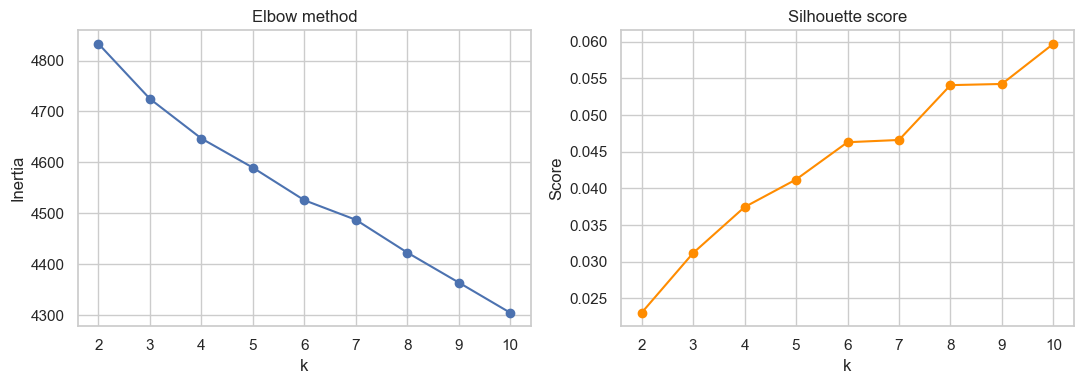

,inertia,silhouette
k,,
2,4832.90,0.0230
3,4724.76,0.0312
4,4646.91,0.0375
5,4589.65,0.0412
6,4525.73,0.0463
7,4487.31,0.0466
8,4422.93,0.0541
9,4364.09,0.0542
10,4304.72,0.0597


In [10]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_lsa)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_lsa, km.labels_, sample_size=3000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
ax[1].plot(ks, sil, "o-", color="darkorange"); ax[1].set(title="Silhouette score", xlabel="k", ylabel="Score")
plt.tight_layout(); plt.savefig("output/kmeans_k_selection.png", dpi=150); plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 2), "silhouette": np.round(sil, 4)}).set_index("k")

## Choice of *k*
* The **elbow curve** decreases smoothly: there is **no clear elbow**.
* The **silhouette score is low for every k** (0.02 to 0.06) and simply increases with k, because splitting the ham messages into many small groups of short generic texts makes tiny improvements. It does not identify a real structure at larger k. Short SMS messages are very sparse and overlapping in vocabulary, so well-separated clusters are not expected.
* **Choice: k = 2.** The data has a natural two-way structure (spam: promotional, formal, number-heavy vs. ham: personal, conversational), and k = 2 gives the most interpretable result: one cluster is clearly promotional and the other conversational, as the top terms and the label comparison below show. Larger k values give only marginally higher silhouette while producing clusters that are harder to interpret.
* *Honest note:* k = 2 has the lowest silhouette of the range tested, so it was chosen for interpretability and domain knowledge, not because the metrics favour it.

In [11]:
K = 2  # chosen for interpretability (see explanation above)

## 2.3 Final K-Means model: cluster sizes & silhouette

In [12]:
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_lsa)
df["cluster"] = km.labels_

sizes = df["cluster"].value_counts().sort_index().rename("n_records").to_frame()
sizes["share_%"] = (sizes["n_records"] / len(df) * 100).round(1)
display(sizes)
print("Silhouette score (full data): %.4f" % silhouette_score(X_lsa, km.labels_))

,n_records,share_%
cluster,,
0,628,12.2
1,4539,87.8


Silhouette score (full data): 0.0222


## 2.4 Distinctive words per cluster
For each cluster the terms with the highest **average TF-IDF weight** among its messages are listed.

In [13]:
terms_all = np.array(tfidf_all.get_feature_names_out())
top_terms = {}
for c in range(K):
    mean_tfidf = np.asarray(X_all[(df["cluster"] == c).values].mean(axis=0)).ravel()
    top_terms[f"Cluster {c}"] = terms_all[np.argsort(mean_tfidf)[::-1][:12]]
top_terms_df = pd.DataFrame(top_terms); top_terms_df.index = range(1, 13)
top_terms_df.to_csv("output/cluster_top_terms.csv")
top_terms_df

,Cluster 0,Cluster 1
1,free,ok
2,txt,just
3,text,come
4,mobile,ll
5,stop,gt
6,reply,lt
7,claim,good
8,prize,like
9,www,got
10,ur,know


## 2.5 Clusters vs. original labels

label,ham,spam,total,spam_%
cluster,,,,
0,78,550,628,87.6
1,4436,103,4539,2.3


Purity: 0.965 | Adjusted Rand Index: 0.801 | NMI: 0.637
Baseline purity (always predict 'ham'): 0.874


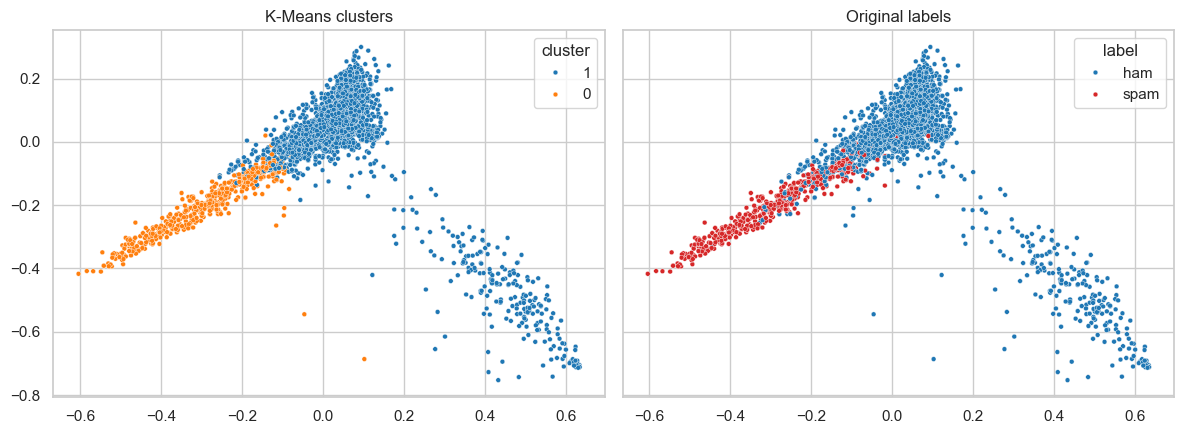

In [14]:
ct = pd.crosstab(df["cluster"], df["label"]); ct["total"] = ct.sum(axis=1)
ct["spam_%"] = (ct["spam"] / ct["total"] * 100).round(1)
display(ct)

purity = pd.crosstab(df["cluster"], df["label"]).max(axis=1).sum() / len(df)
ari = adjusted_rand_score(df["label"], df["cluster"])
nmi = normalized_mutual_info_score(df["label"], df["cluster"])
print(f"Purity: {purity:.3f} | Adjusted Rand Index: {ari:.3f} | NMI: {nmi:.3f}")
print(f"Baseline purity (always predict 'ham'): {1 - df['y'].mean():.3f}")

# Visualise in 2D
pts = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_lsa)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=df["cluster"].astype(str), s=12, ax=ax[0], palette="tab10"); ax[0].set_title("K-Means clusters")
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=df["label"], s=12, ax=ax[1], palette={"ham": "tab:blue", "spam": "tab:red"}); ax[1].set_title("Original labels")
plt.tight_layout(); plt.savefig("output/kmeans_clusters_pca.png", dpi=150); plt.show()

## 2.6 Interpretation of the clustering

* **Cluster sizes:** cluster 0 has 628 messages (12.2%) and cluster 1 has 4,539 (87.8%), close to the real 12.6% / 87.4% spam / ham split.
* **Distinctive words:** cluster 0 is dominated by `free`, `txt`, `text`, `mobile`, `stop`, `reply`, `claim`, `prize`, `cash`, `won`, `www`: typical promotional / call-to-action spam vocabulary. Cluster 1 contains `ok`, `just`, `come`, `ll`, `good`, `like`, `home`, `know`: everyday personal conversation.
* **Agreement with the real labels:** cluster 0 contains 550 of the 653 spam messages and is **87.6% spam**; cluster 1 is **97.7% ham**. Purity is **0.965** against a baseline of 0.874 (always predicting ham), with Adjusted Rand Index = 0.80 and NMI = 0.64. K-Means found the spam/ham split **without ever seeing the labels**.
* **Silhouette score ≈ 0.02:** very low, meaning the clusters overlap heavily and are not sharply separated in the LSA space. The labels agree well with the clusters, but the boundary is fuzzy.
* **Where it goes wrong:** 103 spam messages fall in the ham cluster (short spam, or spam written conversationally) and 78 ham messages fall in the spam cluster (e.g. ham that mentions text, free, call or numbers).
* **Comparison with the supervised model:** the supervised classifier (accuracy 98.5%) is clearly better at the actual task, as expected, since it learns from labels. Clustering is useful for **exploration** and for finding structure when no labels exist.